In [ ]:

from google.colab import drive
from pathlib import Path, PurePosixPath
import zipfile

# Connect Google Drive
drive.mount("/content/drive")

# Your existing dataset ZIP
ZIP_PATH = Path(
    "/content/drive/MyDrive/sugar/dataset.zip"
)

print("ZIP exists:", ZIP_PATH.exists())
print("ZIP location:", ZIP_PATH)


Mounted at /content/drive
ZIP exists: True
ZIP location: /content/drive/MyDrive/sugar/dataset.zip


In [ ]:

import zipfile
from pathlib import PurePosixPath

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    names = z.namelist()

    print("Total ZIP entries:", len(names))
    print("\nFirst 10 entries:")
    for name in names[:10]:
        print(name)

    def inside_folder(name, folder):
        parts = PurePosixPath(name).parts
        return folder in parts[:-1]

    images = sorted([
        n for n in names
        if inside_folder(n, "images")
        and n.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    masks = sorted([
        n for n in names
        if inside_folder(n, "masks")
        and n.lower().endswith(".png")
    ])

    print("\n=== DATASET CHECK ===")
    print("Images found:", len(images))
    print("Masks found:", len(masks))

    print("\nExample image:", images[:2])
    print("Example mask:", masks[:2])

    image_ids = {PurePosixPath(n).stem for n in images}
    mask_ids = {PurePosixPath(n).stem for n in masks}

    print("\nMatching image-mask IDs:",
          len(image_ids & mask_ids))
    print("Images without masks:", len(image_ids - mask_ids))
    print("Masks without images:", len(mask_ids - image_ids))


Total ZIP entries: 206

First 10 entries:
images/DJI_0099__DJI_0000.jpg
images/DJI_0099__DJI_0003.jpg
images/DJI_0099__DJI_0004.jpg
images/DJI_0099__DJI_0005.jpg
images/DJI_0099__DJI_0008.jpg
images/DJI_0099__DJI_0012.jpg
images/DJI_0099__DJI_0013.jpg
images/DJI_0099__DJI_0014.jpg
images/DJI_0099__DJI_0015.jpg
images/DJI_0099__DJI_0018.jpg

=== DATASET CHECK ===
Images found: 102
Masks found: 102

Example image: ['images/DJI_0099__DJI_0000.jpg', 'images/DJI_0099__DJI_0003.jpg']
Example mask: ['masks/DJI_0099__DJI_0000.png', 'masks/DJI_0099__DJI_0003.png']

Matching image-mask IDs: 102
Images without masks: 0
Masks without images: 0


In [ ]:

from pathlib import Path
from PIL import Image
from collections import Counter
import zipfile
import shutil

# Separate directory for the NEW dataset
DATASET_DIR = Path("/content/SugarBeet_102")
IMG_DIR = DATASET_DIR / "images"
MASK_DIR = DATASET_DIR / "masks"

IMG_DIR.mkdir(parents=True, exist_ok=True)
MASK_DIR.mkdir(parents=True, exist_ok=True)

image_map = {Path(p).stem: p for p in images}
mask_map = {Path(p).stem: p for p in masks}

assert len(image_map) == 102
assert len(mask_map) == 102
assert image_map.keys() == mask_map.keys()

ids = sorted(image_map)

# Extract images and masks
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    for image_id in ids:
        for source, destination in [
            (image_map[image_id], IMG_DIR),
            (mask_map[image_id], MASK_DIR)
        ]:
            output = destination / Path(source).name

            with z.open(source) as src, open(output, "wb") as dst:
                shutil.copyfileobj(src, dst)

print("Extraction completed.")

# Validate all image-mask pairs
valid_ids = {0, 1, 2, 255}
problems = []
groups = Counter()

for image_id in ids:
    img_path = IMG_DIR / Path(image_map[image_id]).name
    mask_path = MASK_DIR / Path(mask_map[image_id]).name

    with Image.open(img_path) as img, Image.open(mask_path) as mask:

        if img.size != mask.size:
            problems.append((image_id, "Dimension mismatch"))

        if mask.mode != "L":
            problems.append((image_id, f"Mask mode: {mask.mode}"))
        else:
            values = {
                i for i, count in enumerate(mask.histogram())
                if count > 0
            }

            if not values.issubset(valid_ids):
                problems.append((image_id, "Invalid class IDs"))

    groups[image_id.split("__")[0]] += 1

print("\n=== NEW DATASET VALIDATION ===")
print("Total pairs:", len(ids))
print("Validation problems:", len(problems))
print("Source groups:", dict(sorted(groups.items())))

if problems:
    print("Problems:", problems[:10])
else:
    print("All 102 pairs passed technical validation.")


Extraction completed.

=== NEW DATASET VALIDATION ===
Total pairs: 102
Validation problems: 0
Source groups: {'DJI_0099': 12, 'DJI_0101': 30, 'DJI_0104': 5, 'DJI_0137': 25, 'DJI_0144': 30}
All 102 pairs passed technical validation.


In [ ]:

import pandas as pd
from pathlib import Path

TRAIN_GROUPS = {"DJI_0101", "DJI_0104", "DJI_0144"}
VAL_GROUPS = {"DJI_0137"}
TEST_GROUPS = {"DJI_0099"}

records = []

for image_id in ids:
    group = image_id.split("__")[0]

    if group in TRAIN_GROUPS:
        split = "train"
    elif group in VAL_GROUPS:
        split = "val"
    elif group in TEST_GROUPS:
        split = "test"
    else:
        raise ValueError(f"Unknown group: {group}")

    records.append({
        "image_id": image_id,
        "group": group,
        "split": split,
        "image_path": str(
            IMG_DIR / Path(image_map[image_id]).name
        ),
        "mask_path": str(
            MASK_DIR / Path(mask_map[image_id]).name
        )
    })

df = pd.DataFrame(records)

# Validate the new split
assert len(df) == 102
assert df["image_id"].is_unique

assert df.groupby("split").size().to_dict() == {
    "train": 65,
    "val": 25,
    "test": 12
}

# Confirm no recording group appears in multiple sets
assert df.groupby("group")["split"].nunique().max() == 1

# Save the split manifest
split_file = DATASET_DIR / "split_manifest.csv"
df.to_csv(split_file, index=False)

print("=== NEW DATASET SPLIT ===")
print(df.groupby(["split", "group"]).size())
print("\nTotal images:", len(df))
print("Saved:", split_file)
print("No group overlap detected.")


=== NEW DATASET SPLIT ===
split  group   
test   DJI_0099    12
train  DJI_0101    30
       DJI_0104     5
       DJI_0144    30
val    DJI_0137    25
dtype: int64

Total images: 102
Saved: /content/SugarBeet_102/split_manifest.csv
No group overlap detected.


In [ ]:

import torch
import numpy as np
import random

from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader

PATCH_SIZE = 512

class SugarBeetDataset(Dataset):
    def __init__(self, frame, patch_size=512, augment=False):
        self.patch_size = patch_size
        self.augment = augment
        self.samples = []

        for row in frame.itertuples(index=False):
            with Image.open(row.image_path) as img:
                width, height = img.size

            for y in range(0, height, patch_size):
                for x in range(0, width, patch_size):
                    self.samples.append((
                        row.image_path,
                        row.mask_path,
                        x, y
                    ))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        image_path, mask_path, x, y = self.samples[idx]
        p = self.patch_size

        with Image.open(image_path) as im:
            im = im.convert("RGB")
            image = im.crop((
                x, y,
                min(x+p, im.width),
                min(y+p, im.height)
            ))

        with Image.open(mask_path) as m:
            assert m.mode == "L"
            mask = m.crop((
                x, y,
                min(x+p, m.width),
                min(y+p, m.height)
            ))

        # Pad image and mask consistently
        right = p - image.width
        bottom = p - image.height

        image = ImageOps.expand(
            image, (0, 0, right, bottom), fill=0
        )
        mask = ImageOps.expand(
            mask, (0, 0, right, bottom), fill=255
        )

        image = torch.from_numpy(
            np.array(image, dtype=np.float32)
            .transpose(2, 0, 1).copy()
        ) / 255.0

        mask = torch.from_numpy(
            np.array(mask, dtype=np.int64).copy()
        )

        if self.augment:
            if random.random() < 0.5:
                image = torch.flip(image, [2])
                mask = torch.flip(mask, [1])

            if random.random() < 0.5:
                image = torch.flip(image, [1])
                mask = torch.flip(mask, [0])

        return image, mask


# Rebuild using the NEW 102-image split
train_dataset = SugarBeetDataset(
    df[df.split == "train"],
    augment=True
)

val_dataset = SugarBeetDataset(
    df[df.split == "val"],
    augment=False
)

test_dataset = SugarBeetDataset(
    df[df.split == "test"],
    augment=False
)

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2
)

print("=== NEW PATCH DATASET ===")
print("Training patches:", len(train_dataset))
print("Validation patches:", len(val_dataset))
print("Testing patches:", len(test_dataset))

images_batch, masks_batch = next(iter(train_loader))

assert images_batch.shape == (4, 3, 512, 512)
assert masks_batch.shape == (4, 512, 512)
assert set(torch.unique(masks_batch).tolist()) <= {0, 1, 2, 255}

print("Batch validation passed.")
print("GPU available:", torch.cuda.is_available())


=== NEW PATCH DATASET ===
Training patches: 2600
Validation patches: 1000
Testing patches: 480
Batch validation passed.
GPU available: True


In [ ]:

import torch
import numpy as np
from PIL import Image
from collections import defaultdict
from torch.utils.data import WeightedRandomSampler, DataLoader

# Analyze TRAINING patches only
weed_flags = np.zeros(len(train_dataset), dtype=bool)
patches_by_mask = defaultdict(list)

for idx, (_, mask_path, x, y) in enumerate(train_dataset.samples):
    patches_by_mask[mask_path].append((idx, x, y))

for mask_path, patches in patches_by_mask.items():
    with Image.open(mask_path) as m:
        mask_array = np.array(m, dtype=np.uint8)

    for idx, x, y in patches:
        patch = mask_array[
            y:y + PATCH_SIZE,
            x:x + PATCH_SIZE
        ]
        weed_flags[idx] = np.any(patch == 2)

weed_count = int(weed_flags.sum())
other_count = len(weed_flags) - weed_count

assert weed_count > 0, "No weed patches found."
assert other_count > 0, "No non-weed patches found."

# Target: 35% weed-containing patches
WEED_TARGET = 0.35

weights = np.where(
    weed_flags,
    WEED_TARGET / weed_count,
    (1 - WEED_TARGET) / other_count
)

sampler = WeightedRandomSampler(
    weights=torch.tensor(weights, dtype=torch.double),
    num_samples=len(train_dataset),
    replacement=True,
    generator=torch.Generator().manual_seed(42)
)

# Replace ONLY the training loader
train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    sampler=sampler,
    num_workers=2,
    pin_memory=True
)

print("=== NEW WEED-AWARE SAMPLING ===")
print("Total training patches:", len(train_dataset))
print("Patches containing weeds:", weed_count)
print("Patches without weeds:", other_count)
print("Original weed percentage:",
      round(100 * weed_count / len(train_dataset), 2))
print("Target weed sampling: 35%")
print("Sampler ready.")


=== NEW WEED-AWARE SAMPLING ===
Total training patches: 2600
Patches containing weeds: 369
Patches without weeds: 2231
Original weed percentage: 14.19
Target weed sampling: 35%
Sampler ready.


In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F
import random
import numpy as np

# Reproducibility
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)
np.random.seed(42)
random.seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()

        self.pool = nn.MaxPool2d(2)

        self.enc1 = ConvBlock(3, 16)
        self.enc2 = ConvBlock(16, 32)
        self.enc3 = ConvBlock(32, 64)
        self.enc4 = ConvBlock(64, 128)

        self.bottleneck = ConvBlock(128, 256)

        self.dec4 = ConvBlock(384, 128)
        self.dec3 = ConvBlock(192, 64)
        self.dec2 = ConvBlock(96, 32)
        self.dec1 = ConvBlock(48, 16)

        self.output = nn.Conv2d(16, num_classes, 1)

    def upsample(self, x, skip):
        x = F.interpolate(
            x,
            size=skip.shape[2:],
            mode="bilinear",
            align_corners=False
        )
        return torch.cat([x, skip], dim=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.dec4(self.upsample(b, e4))
        d3 = self.dec3(self.upsample(d4, e3))
        d2 = self.dec2(self.upsample(d3, e2))
        d1 = self.dec1(self.upsample(d2, e1))

        return self.output(d1)


# Fresh model — no old checkpoint loaded
model = UNet(num_classes=3).to(device)

print("Device:", device)
print("Model:", type(model).__name__)
print("Parameters:", sum(
    p.numel() for p in model.parameters()
))

# Test forward pass
images_batch, masks_batch = next(iter(train_loader))

model.eval()
with torch.no_grad():
    outputs = model(images_batch.to(device))

print("Input:", images_batch.shape)
print("Output:", outputs.shape)

assert outputs.shape == (4, 3, 512, 512)
print(" U-Net ready for training.")


Device: cuda
Model: UNet
Parameters: 1965603
Input: torch.Size([4, 3, 512, 512])
Output: torch.Size([4, 3, 512, 512])
 U-Net ready for training.


In [ ]:

import numpy as np
import torch
import torch.nn as nn
from pathlib import Path
from PIL import Image

# Count class pixels from TRAINING images only
class_counts = np.zeros(3, dtype=np.int64)

for mask_path in df.loc[df["split"] == "train", "mask_path"]:
    with Image.open(mask_path) as mask:
        hist = np.array(mask.histogram())
        class_counts += hist[[0, 1, 2]]

frequencies = class_counts / class_counts.sum()

# Moderate class balancing
weights = np.sqrt(
    frequencies.max() / np.maximum(frequencies, 1e-9)
)
weights = np.clip(weights, 1.0, 5.0)

class_weights = torch.tensor(
    weights,
    dtype=torch.float32,
    device=device
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    ignore_index=255
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0003,
    weight_decay=0.0001
)

# Separate directory: preserve previous 97-image model
SAVE_DIR = Path(
    "/content/drive/MyDrive/sugar/UNet_102_results"
)
SAVE_DIR.mkdir(parents=True, exist_ok=True)

checkpoint_path = SAVE_DIR / "best_unet_102.pt"

history = []
best_iou = -1.0

print("=== TRAINING CONFIGURATION ===")

for name, freq, weight in zip(
    ["Background", "Sugar beet", "Weed"],
    frequencies,
    weights
):
    print(f"{name}: {freq*100:.3f}% | weight={weight:.2f}")

print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Loss: Weighted CrossEntropy")
print("Ignore index: 255")
print("Checkpoint:", checkpoint_path)
print("Training configuration ready.")


=== TRAINING CONFIGURATION ===
Background: 81.303% | weight=1.00
Sugar beet: 18.217% | weight=2.11
Weed: 0.480% | weight=5.00
Learning rate: 0.0003
Loss: Weighted CrossEntropy
Ignore index: 255
Checkpoint: /content/drive/MyDrive/sugar/UNet_102_results/best_unet_102.pt
Training configuration ready.


In [ ]:

import torch
import numpy as np
import pandas as pd

MAX_EPOCHS = 20
PATIENCE = 5

best_iou = -1.0
epochs_without_improvement = 0
history = []

use_amp = device.type == "cuda"

scaler = torch.amp.GradScaler(
    "cuda", enabled=use_amp
)

for epoch in range(MAX_EPOCHS):

    # ===== TRAINING =====
    model.train()
    train_loss_total = 0.0

    for imgs, masks in train_loader:
        imgs = imgs.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            enabled=use_amp
        ):
            outputs = model(imgs)
            loss = criterion(outputs, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss_total += loss.item()

    train_loss = train_loss_total / len(train_loader)

    # ===== VALIDATION =====
    model.eval()
    val_loss_total = 0.0

    # Rows = ground truth, columns = predictions
    confusion = torch.zeros(
        (3, 3), dtype=torch.long, device=device
    )

    with torch.inference_mode():
        for imgs, masks in val_loader:
            imgs = imgs.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            with torch.autocast(
                device_type=device.type,
                enabled=use_amp
            ):
                outputs = model(imgs)
                loss = criterion(outputs, masks)

            val_loss_total += loss.item()

            predictions = outputs.argmax(dim=1)

            valid = masks != 255
            gt = masks[valid]
            pred = predictions[valid]

            counts = torch.bincount(
                gt * 3 + pred, minlength=9
            ).reshape(3, 3)

            confusion += counts

    val_loss = val_loss_total / len(val_loader)

    cm = confusion.cpu().numpy()

    intersection = np.diag(cm).astype(float)
    gt_pixels = cm.sum(axis=1).astype(float)
    pred_pixels = cm.sum(axis=0).astype(float)

    union = gt_pixels + pred_pixels - intersection

    iou = np.divide(
        intersection, union,
        out=np.full(3, np.nan),
        where=union > 0
    )

    weed_precision = intersection[2] / max(pred_pixels[2], 1)
    weed_recall = intersection[2] / max(gt_pixels[2], 1)

    crop_weed_mean = float(np.nanmean(iou[1:3]))

    record = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "sugar_beet_iou": iou[1],
        "weed_iou": iou[2],
        "crop_weed_mean_iou": crop_weed_mean,
        "weed_precision": weed_precision,
        "weed_recall": weed_recall,
        "crop_pixels_predicted_as_weed": int(cm[1, 2])
    }

    history.append(record)

    print(f"\n===== EPOCH {epoch+1}/{MAX_EPOCHS} =====", flush=True)
    print(f"Train loss: {train_loss:.4f}")
    print(f"Validation loss: {val_loss:.4f}")
    print(f"Sugar beet IoU: {iou[1]:.4f}")
    print(f"Weed IoU: {iou[2]:.4f}")
    print(f"Crop/weed mean IoU: {crop_weed_mean:.4f}")
    print(f"Weed precision: {weed_precision:.4f}")
    print(f"Weed recall: {weed_recall:.4f}")
    print(f"Crop pixels mistaken for weed: {cm[1,2]}")

    # Save the training history every epoch
    pd.DataFrame(history).to_csv(
        SAVE_DIR / "training_history_102.csv",
        index=False
    )

    # Save best model using the validation score
    if crop_weed_mean > best_iou + 0.001:
        best_iou = crop_weed_mean
        epochs_without_improvement = 0

        torch.save(
            model.state_dict(),
            checkpoint_path
        )

        print("Best model saved.", flush=True)
    else:
        epochs_without_improvement += 1
        print(
            f"No improvement: {epochs_without_improvement}/{PATIENCE}",
            flush=True
        )

    if epochs_without_improvement >= PATIENCE:
        print("\nEarly stopping activated.")
        break

print("\n=== TRAINING COMPLETED ===")
print("Best validation crop/weed mean IoU:", best_iou)
print("Best model:", checkpoint_path)



===== EPOCH 1/20 =====
Train loss: 0.4683
Validation loss: 0.1784
Sugar beet IoU: 0.7916
Weed IoU: 0.1471
Crop/weed mean IoU: 0.4693
Weed precision: 0.1697
Weed recall: 0.5243
Crop pixels mistaken for weed: 301998
Best model saved.

===== EPOCH 2/20 =====
Train loss: 0.2425
Validation loss: 0.1162
Sugar beet IoU: 0.8015
Weed IoU: 0.2375
Crop/weed mean IoU: 0.5195
Weed precision: 0.3035
Weed recall: 0.5221
Crop pixels mistaken for weed: 262038
Best model saved.

===== EPOCH 3/20 =====
Train loss: 0.2065
Validation loss: 0.0979
Sugar beet IoU: 0.8395
Weed IoU: 0.2675
Crop/weed mean IoU: 0.5535
Weed precision: 0.4054
Weed recall: 0.4401
Crop pixels mistaken for weed: 121564
Best model saved.

===== EPOCH 4/20 =====
Train loss: 0.1904
Validation loss: 0.0981
Sugar beet IoU: 0.8463
Weed IoU: 0.2511
Crop/weed mean IoU: 0.5487
Weed precision: 0.2919
Weed recall: 0.6420
Crop pixels mistaken for weed: 144197
No improvement: 1/5

===== EPOCH 5/20 =====
Train loss: 0.1775
Validation loss: 0.0872

In [11]:

from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

SAVE_DIR = Path("/content/drive/MyDrive/sugar/UNet_102_results")

checkpoint_path = SAVE_DIR / "best_unet_102.pt"
history_path = SAVE_DIR / "training_history_102.csv"

print("Model saved:", checkpoint_path.exists())
print("Training history saved:", history_path.exists())

if checkpoint_path.exists():
    print("Model size (MB):",
          round(checkpoint_path.stat().st_size / 1024**2, 2))

if history_path.exists():
    import pandas as pd
    history_df = pd.read_csv(history_path)
    print("Completed epochs:", len(history_df))
    print("Best epoch:",
          history_df.loc[
              history_df["crop_weed_mean_iou"].idxmax(),
              "epoch"
          ])


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved: True
Training history saved: True
Model size (MB): 7.55
Completed epochs: 14
Best epoch: 9


In [12]:

import torch
import numpy as np

# Check whether Colab still has the required objects
required = ["model", "test_loader", "device"]
missing = [name for name in required if name not in globals()]

if missing:
    print("Missing from Colab memory:", missing)
    print("Rerun setup Steps 1-5 and Step 7.")
    print("Do NOT rerun training Steps 8 or 9.")

else:
    # Load the best saved model (Epoch 9)
    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=True
        )
    )

    model.eval()
    confusion = torch.zeros(
        (3, 3), dtype=torch.long, device=device
    )

    # Evaluate on untouched test images
    with torch.inference_mode():
        for images, masks in test_loader:
            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            valid = masks != 255
            truth = masks[valid]
            pred = predictions[valid]

            confusion += torch.bincount(
                truth * 3 + pred,
                minlength=9
            ).reshape(3, 3)

    cm = confusion.cpu().numpy()

    print("=== FINAL TEST RESULTS ===")

    names = ["Background", "Sugar beet", "Weed"]

    for c, name in enumerate(names):
        tp = cm[c, c]
        actual = cm[c, :].sum()
        predicted = cm[:, c].sum()
        union = actual + predicted - tp

        iou = tp / union if union > 0 else float("nan")
        precision = tp / predicted if predicted > 0 else 0.0
        recall = tp / actual if actual > 0 else 0.0

        print(f"\n{name}")
        print(f"  IoU:       {iou:.4f}")
        print(f"  Precision: {precision:.4f}")
        print(f"  Recall:    {recall:.4f}")

    print("\nCrop pixels mistaken for weed:", cm[1, 2])
    print("\nTest evaluation completed.")


=== FINAL TEST RESULTS ===

Background
  IoU:       0.9696
  Precision: 0.9940
  Recall:    0.9753

Sugar beet
  IoU:       0.8524
  Precision: 0.8724
  Recall:    0.9738

Weed
  IoU:       0.3323
  Precision: 0.6489
  Recall:    0.4052

Crop pixels mistaken for weed: 32006

Test evaluation completed.


In [15]:

import pandas as pd
import numpy as np

class_names = ["Background", "Sugar beet", "Weed"]
rows = []

for c, name in enumerate(class_names):
    tp = cm[c, c]
    actual = cm[c, :].sum()
    predicted = cm[:, c].sum()
    union = actual + predicted - tp

    rows.append({
        "class": name,
        "iou": tp / union if union > 0 else np.nan,
        "precision": tp / predicted if predicted > 0 else np.nan,
        "recall": tp / actual if actual > 0 else np.nan
    })

results_df = pd.DataFrame(rows)

results_df.to_csv(
    SAVE_DIR / "test_metrics_102.csv",
    index=False
)

pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
).to_csv(SAVE_DIR / "test_confusion_matrix_102.csv")

print(results_df.round(4).to_string(index=False))
print("\nFinal test results saved to Google Drive.")


     class    iou  precision  recall
Background 0.9696     0.9940  0.9753
Sugar beet 0.8524     0.8724  0.9738
      Weed 0.3323     0.6489  0.4052

Final test results saved to Google Drive.


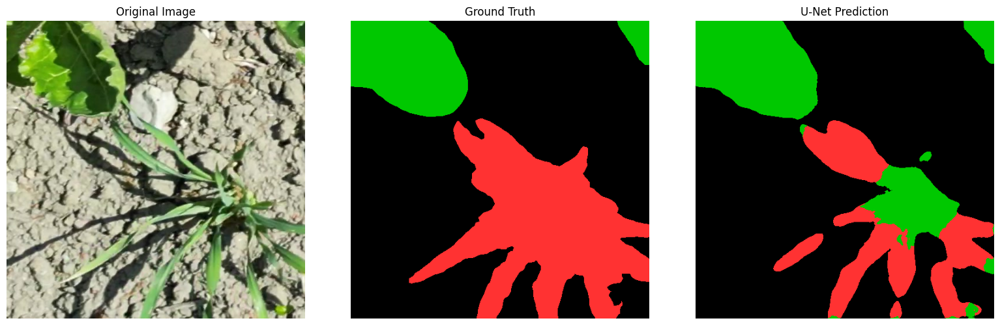

Test patch index: 345
Ground-truth weed pixels: 65844
Visualization completed.


In [16]:

import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

# Load our best trained model
model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
)
model.eval()

# Find a test patch containing weeds
best_idx = None
most_weeds = -1
last_mask_path = None

for idx, (img_path, mask_path, x, y) in enumerate(test_dataset.samples):

    if mask_path != last_mask_path:
        with Image.open(mask_path) as mask:
            full_mask = np.array(mask)
        last_mask_path = mask_path

    patch_mask = full_mask[y:y+512, x:x+512]
    weed_pixels = np.count_nonzero(patch_mask == 2)

    if weed_pixels > most_weeds:
        most_weeds = weed_pixels
        best_idx = idx

# Load selected test patch
image_tensor, ground_truth = test_dataset[best_idx]

# Predict segmentation
with torch.inference_mode():
    prediction = model(
        image_tensor.unsqueeze(0).to(device)
    ).argmax(dim=1).squeeze(0).cpu().numpy()

# Convert tensors to images
original = image_tensor.permute(1, 2, 0).numpy()
ground_truth = ground_truth.numpy()

# Colors: background=black, crop=green, weed=red
def colorize(mask):
    result = np.zeros((*mask.shape, 3), dtype=np.uint8)
    result[mask == 1] = [0, 200, 0]
    result[mask == 2] = [255, 50, 50]
    result[mask == 255] = [120, 120, 120]
    return result

# Display comparison
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(original)
axes[0].set_title("Original Image")

axes[1].imshow(colorize(ground_truth))
axes[1].set_title("Ground Truth")

axes[2].imshow(colorize(prediction))
axes[2].set_title("U-Net Prediction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Test patch index:", best_idx)
print("Ground-truth weed pixels:", most_weeds)
print("Visualization completed.")


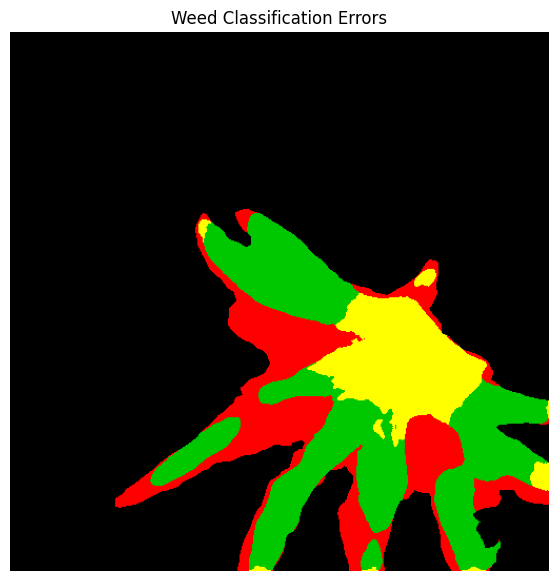

Green: Correctly detected weed
Yellow: Weed mistaken for sugar beet
Red: Weed mistaken for background
Magenta: Sugar beet mistaken for weed

Weed pixels correctly detected: 31394
Weed pixels mistaken for crop: 13555
Weed pixels mistaken for background: 20895
Crop pixels mistaken for weed: 0


In [18]:

import numpy as np
import matplotlib.pyplot as plt

# Compare ground truth and prediction
valid = ground_truth != 255

correct_weed = valid & (ground_truth == 2) & (prediction == 2)
weed_as_crop = valid & (ground_truth == 2) & (prediction == 1)
weed_as_background = valid & (ground_truth == 2) & (prediction == 0)
crop_as_weed = valid & (ground_truth == 1) & (prediction == 2)

# Create error visualization
error_image = np.zeros((*ground_truth.shape, 3), dtype=np.uint8)

error_image[correct_weed] = [0, 200, 0]       # Green
error_image[weed_as_crop] = [255, 255, 0]      # Yellow
error_image[weed_as_background] = [255, 0, 0]  # Red
error_image[crop_as_weed] = [255, 0, 255]      # Magenta

plt.figure(figsize=(7, 7))
plt.imshow(error_image)
plt.title("Weed Classification Errors")
plt.axis("off")
plt.show()

print("Green: Correctly detected weed")
print("Yellow: Weed mistaken for sugar beet")
print("Red: Weed mistaken for background")
print("Magenta: Sugar beet mistaken for weed")

print("\nWeed pixels correctly detected:", int(correct_weed.sum()))
print("Weed pixels mistaken for crop:", int(weed_as_crop.sum()))
print("Weed pixels mistaken for background:", int(weed_as_background.sum()))
print("Crop pixels mistaken for weed:", int(crop_as_weed.sum()))


Training images with zero weed labels: 13

Image names:
DJI_0101__DJI_0018
DJI_0101__DJI_0019
DJI_0101__DJI_0024
DJI_0144__DJI_0017
DJI_0144__DJI_0018
DJI_0144__DJI_0019
DJI_0144__DJI_0021
DJI_0144__DJI_0022
DJI_0144__DJI_0023
DJI_0144__DJI_0024
DJI_0144__DJI_0044
DJI_0144__DJI_0045
DJI_0144__DJI_0084


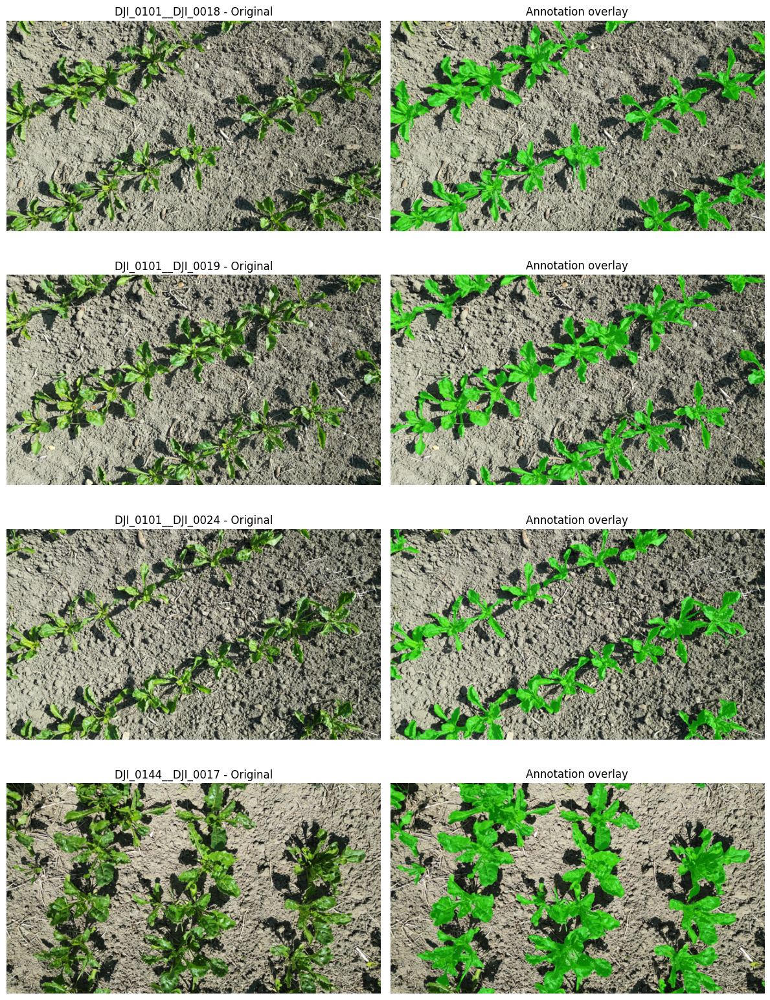

In [19]:

from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Find training images containing zero weed labels
zero_weed_train = []

for row in df[df["split"] == "train"].itertuples(index=False):
    with Image.open(row.mask_path) as mask:
        if mask.histogram()[2] == 0:
            zero_weed_train.append(row)

print("Training images with zero weed labels:",
      len(zero_weed_train))

print("\nImage names:")
for row in zero_weed_train:
    print(row.image_id)

# Display first four images and their annotations
n = min(4, len(zero_weed_train))

if n > 0:
    fig, axes = plt.subplots(n, 2, figsize=(12, 4*n))
    axes = np.array(axes).reshape(n, 2)

    for i, row in enumerate(zero_weed_train[:n]):
        with Image.open(row.image_path) as im:
            im = im.convert("RGB")
            im.thumbnail((640, 360))
            image = np.array(im)

        with Image.open(row.mask_path) as m:
            m = m.resize(
                (image.shape[1], image.shape[0]),
                Image.Resampling.NEAREST
            )
            mask = np.array(m)

        overlay = image.copy()

        # Highlight annotated sugar beet in green
        crop = mask == 1
        overlay[crop] = (
            0.6 * image[crop] +
            0.4 * np.array([0, 255, 0])
        ).astype(np.uint8)

        axes[i, 0].imshow(image)
        axes[i, 0].set_title(row.image_id + " - Original")

        axes[i, 1].imshow(overlay)
        axes[i, 1].set_title("Annotation overlay")

        for ax in axes[i]:
            ax.axis("off")

    plt.tight_layout()
    plt.show()


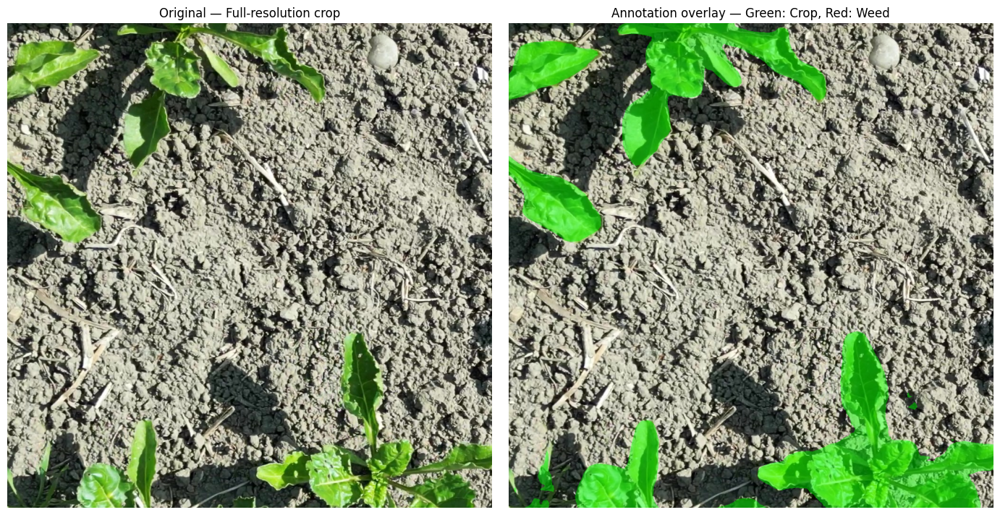

Image: DJI_0101__DJI_0018
Crop position: 1150 400
Weed pixels in crop: 0


In [20]:

from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Select one image for detailed annotation inspection
image_id = "DJI_0101__DJI_0018"

row = df.loc[df["image_id"] == image_id].iloc[0]

with Image.open(row["image_path"]) as im:
    image = np.array(im.convert("RGB"))

with Image.open(row["mask_path"]) as m:
    mask = np.array(m)

# Inspect a 1024 x 1024 region at original resolution
x, y = 1150, 400
size = 1024

original_crop = image[y:y+size, x:x+size]
mask_crop = mask[y:y+size, x:x+size]

overlay = original_crop.copy()

# Green = sugar beet, red = weed
colors = {
    1: np.array([0, 255, 0]),
    2: np.array([255, 0, 0])
}

for class_id, color in colors.items():
    selected = mask_crop == class_id
    overlay[selected] = (
        0.55 * original_crop[selected]
        + 0.45 * color
    ).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(original_crop)
axes[0].set_title("Original — Full-resolution crop")

axes[1].imshow(overlay)
axes[1].set_title("Annotation overlay — Green: Crop, Red: Weed")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Image:", image_id)
print("Crop position:", x, y)
print("Weed pixels in crop:", np.count_nonzero(mask_crop == 2))



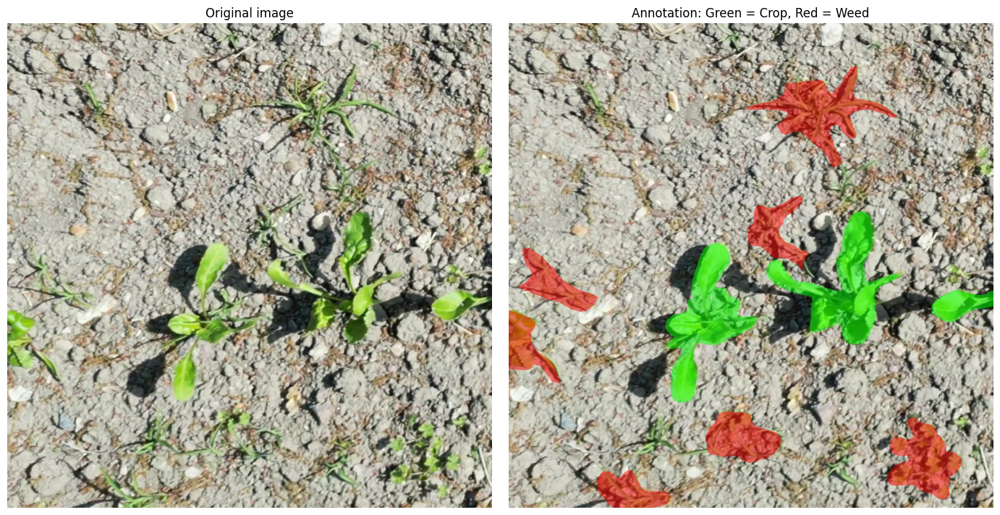

Image: DJI_0104__DJI_0003
Total weed pixels in image: 335303
Weed pixels in selected region: 83412
Region coordinates: (0, 1136)


In [21]:

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Find the training image with the most weed pixels
train_rows = df[df["split"] == "train"]

weed_counts = []

for row in train_rows.itertuples(index=False):
    with Image.open(row.mask_path) as mask:
        count = mask.histogram()[2]
    weed_counts.append((count, row))

weed_counts.sort(key=lambda item: item[0], reverse=True)

count, selected = weed_counts[0]

with Image.open(selected.image_path) as im:
    image = np.array(im.convert("RGB"))

with Image.open(selected.mask_path) as m:
    mask = np.array(m)

# Find a 1024x1024 region rich in weeds
size = 1024
height, width = mask.shape

xs = list(range(0, width - size + 1, 512))
ys = list(range(0, height - size + 1, 512))

xs.append(width - size)
ys.append(height - size)

best = (-1, 0, 0)

for y in sorted(set(ys)):
    for x in sorted(set(xs)):
        n = np.count_nonzero(
            mask[y:y+size, x:x+size] == 2
        )
        if n > best[0]:
            best = (n, x, y)

weed_pixels, x, y = best

original = image[y:y+size, x:x+size]
labels = mask[y:y+size, x:x+size]

overlay = original.copy()

for class_id, color in [
    (1, np.array([0, 255, 0])),
    (2, np.array([255, 0, 0]))
]:
    selected_pixels = labels == class_id
    overlay[selected_pixels] = (
        0.5 * original[selected_pixels] + 0.5 * color
    ).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(original)
axes[0].set_title("Original image")

axes[1].imshow(overlay)
axes[1].set_title("Annotation: Green = Crop, Red = Weed")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Image:", selected.image_id)
print("Total weed pixels in image:", count)
print("Weed pixels in selected region:", weed_pixels)
print("Region coordinates:", (x, y))


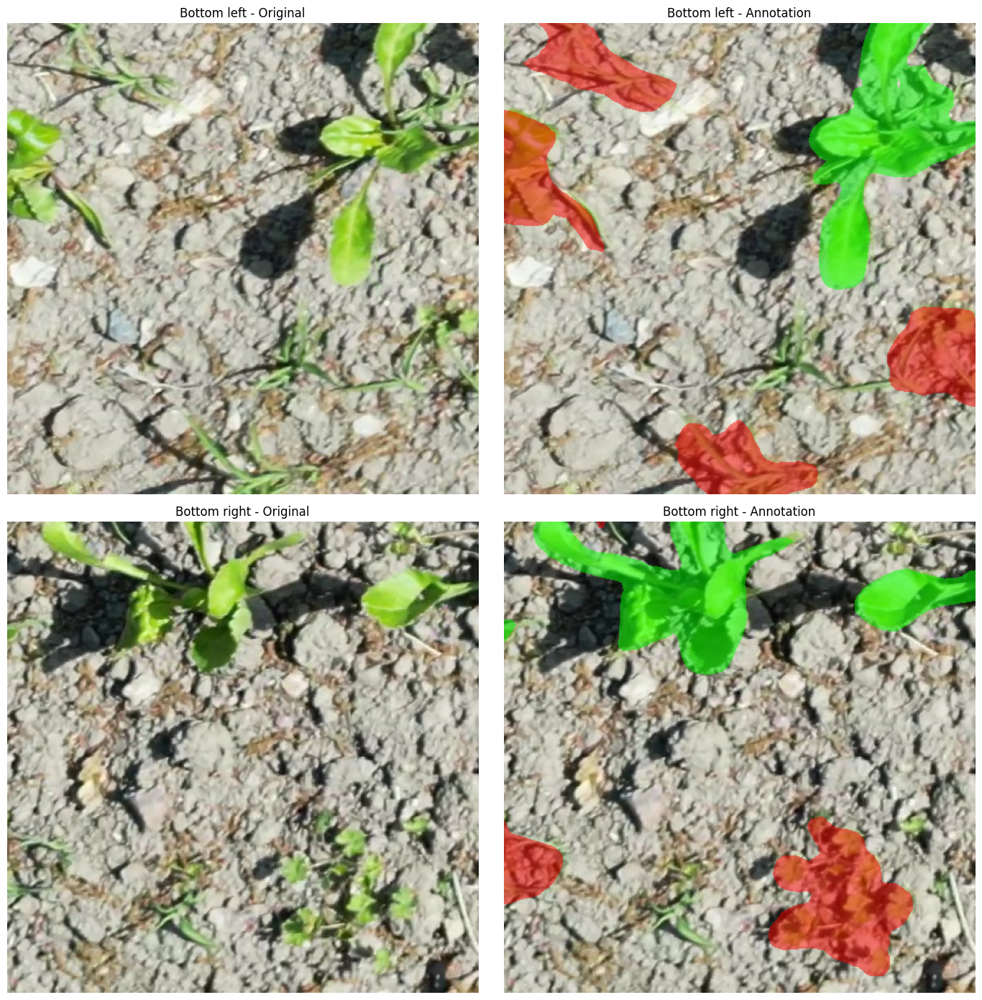

In [22]:

import matplotlib.pyplot as plt

# Bottom half of the selected 1024 x 1024 region
bottom_original = original[512:1024, 0:1024]
bottom_overlay = overlay[512:1024, 0:1024]

fig, axes = plt.subplots(2, 2, figsize=(14, 14))

# Left half
axes[0, 0].imshow(bottom_original[:, :512])
axes[0, 0].set_title("Bottom left - Original")

axes[0, 1].imshow(bottom_overlay[:, :512])
axes[0, 1].set_title("Bottom left - Annotation")

# Right half
axes[1, 0].imshow(bottom_original[:, 512:])
axes[1, 0].set_title("Bottom right - Original")

axes[1, 1].imshow(bottom_overlay[:, 512:])
axes[1, 1].set_title("Bottom right - Annotation")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()


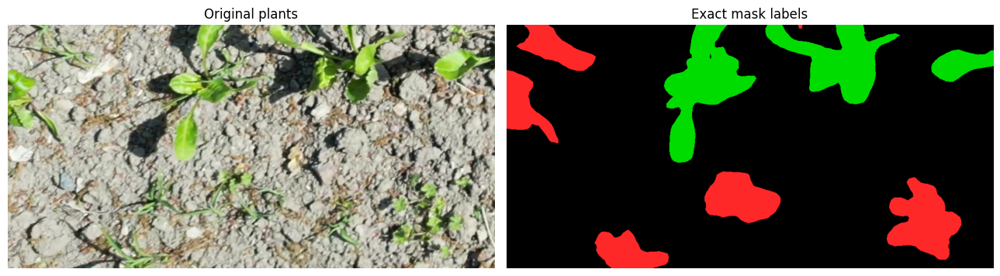

Black = Background (0)
Green = Sugar beet (1)
Red = Weed (2)
Purple = Ignore (255)
Class 0: 423751 pixels
Class 1: 49370 pixels
Class 2: 51167 pixels
Class 255: 0 pixels


In [23]:

import numpy as np
import matplotlib.pyplot as plt

# Use the same weed-rich region from Step 17
bottom_mask = labels[512:1024, :1024]

# Colors for every mask class
colors = np.array([
    [0, 0, 0],        # 0 = Background
    [0, 220, 0],      # 1 = Sugar beet
    [255, 40, 40],    # 2 = Weed
], dtype=np.uint8)

colored = np.zeros((*bottom_mask.shape, 3), dtype=np.uint8)

for class_id in range(3):
    colored[bottom_mask == class_id] = colors[class_id]

# Purple = ignored pixels
colored[bottom_mask == 255] = [180, 0, 255]

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

axes[0].imshow(bottom_original)
axes[0].set_title("Original plants")

axes[1].imshow(colored)
axes[1].set_title("Exact mask labels")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Black = Background (0)")
print("Green = Sugar beet (1)")
print("Red = Weed (2)")
print("Purple = Ignore (255)")

for value in [0, 1, 2, 255]:
    print(
        f"Class {value}:",
        int(np.count_nonzero(bottom_mask == value)),
        "pixels"
    )



In [24]:

from pathlib import Path
from PIL import Image
import numpy as np

# Image with possible missing weed annotations
image_id = "DJI_0104__DJI_0003"

# Region identified in our previous inspection
x, y = 0, 1648
width, height = 1024, 512

row = df.loc[df["image_id"] == image_id].iloc[0]

review_dir = Path(
    "/content/drive/MyDrive/sugar/annotation_review"
)
review_dir.mkdir(parents=True, exist_ok=True)

with Image.open(row["image_path"]) as im:
    original = im.convert("RGB").crop(
        (x, y, x + width, y + height)
    )

with Image.open(row["mask_path"]) as m:
    mask = m.crop(
        (x, y, x + width, y + height)
    )

# Make a visible colour version of the labels
mask_array = np.array(mask)
colors = np.zeros((height, width, 3), dtype=np.uint8)

colors[mask_array == 1] = [0, 255, 0]
colors[mask_array == 2] = [255, 0, 0]
colors[mask_array == 255] = [180, 0, 255]

overlay = Image.blend(
    original,
    Image.fromarray(colors),
    alpha=0.35
)

# Save separate files without changing the dataset
original.save(review_dir / "suspect_original.png")
mask.save(review_dir / "suspect_mask.png")
overlay.save(review_dir / "suspect_overlay.png")

print("Annotation review files saved.")
print("Folder:", review_dir)
print("Image:", image_id)
print("Coordinates:", (x, y, width, height))
print("Original dataset unchanged.")


Annotation review files saved.
Folder: /content/drive/MyDrive/sugar/annotation_review
Image: DJI_0104__DJI_0003
Coordinates: (0, 1648, 1024, 512)
Original dataset unchanged.
